In [17]:
#step 2

from pathlib import Path
import pandas as pd
from PIL import Image

# 1. Define paths based on your local directory structure
base_dir = Path(r"C:\Users\Helen\Desktop\Chris Ironhack\Week 3\Week 2")
csv_path = base_dir / "styles.csv"
images_dir = base_dir / "images"

print("Loading local product dataset...")

# Initialize products_df beforehand to prevent NameError
products_df = pd.DataFrame()

try:
  # 2. Try loading the local styles.csv file and skip any bad/malformed lines
  products_df = pd.read_csv(csv_path, on_bad_lines="skip")

  # Take the first 100 samples for the lab
  products_df = products_df.head(100)
  print(f"✓ Loaded {len(products_df)} products from local CSV")
  print(f"Dataset columns: {products_df.columns.tolist()}")

except Exception as e:
  print(f"⚠ Could not load local CSV: {e}")
  # ... fallback code ...

  # Fallback sample data if CSV loading fails
  products_data = [
      {
          "id": 1,
          "name": "Wireless Headphones",
          "price": 79.99,
          "category": "Electronics",
          "image_path": "images/product1.jpg",
      }
  ]
  products_df = pd.DataFrame(products_data)

# 3. Verify images directory exists
if images_dir.exists():
  print(f"✓ Images directory found at: {images_dir}")
else:
  print(f"⚠ Warning: Images directory not found at {images_dir}")

print(f"\n✓ Dataset prepared!")
print(f"  Total products: {len(products_df)}")

Loading local product dataset...
✓ Loaded 100 products from local CSV
Dataset columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']
✓ Images directory found at: C:\Users\Helen\Desktop\Chris Ironhack\Week 3\Week 2\images

✓ Dataset prepared!
  Total products: 100


--- First Row Data ---
id: 15970
gender: Men
masterCategory: Apparel
subCategory: Topwear
articleType: Shirts
baseColour: Navy Blue
season: Fall
year: 2011.0
usage: Casual
productDisplayName: Turtle Check Men Navy Blue Shirt

Looking for image at: C:\Users\Helen\Desktop\Chris Ironhack\Week 3\Week 2\images\15970.jpg
File Exists: True


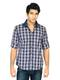

In [18]:
# Step2  verify that the image paths in the DataFrame exist
from pathlib import Path
from PIL import Image

# 1. Grab the first row
row = products_df.iloc[0]

# 2. Print all columns and their values for this first row
print("--- First Row Data ---")
for col, val in row.items():
  print(f"{col}: {val}")

# 3. Automatically find an image if there's a filename column (or fallback to row index)
# (Adjust 'image' or 'filename' if your CSV uses a different column name)
image_col = None
for col in ["image", "filename", "img", "id"]:
  if col in products_df.columns:
    image_col = col
    break

if image_col:
  filename = f"{row[image_col]}.jpg"
else:
  # Fallback to the very first column or row index (0)
  filename = f"{row.iloc[0]}.jpg"

image_path = images_dir / filename
print(f"\nLooking for image at: {image_path}")
print(f"File Exists: {image_path.exists()}")

# 4. Display the image if it exists
if image_path.exists():
  display(Image.open(image_path))
else:
  print("Image not found with that filename pattern. Check your column names above!")

In [23]:
# Step 3

import base64

def encode_image_to_base64(image_path):
    """Encode an image file to base64 string."""
    with open(image_path, "rb") as img_file: # rb opens the binary file for reading
        encoded = base64.b64encode(img_file.read()).decode("utf-8") # file conversion to ascii string
    return encoded

row = products_df.iloc[0] # using the first row for demonstration to be consistent with the previous step
product_id = row['id']

sample_path = images_dir / f"{product_id}.jpg"

# 3. Encode the image
print(f"\nVerification")
encoded_image = encode_image_to_base64(sample_path)
print(f"Encoded image length: {len(encoded_image)} characters")
print(f"Encoded prefix: {encoded_image[:40]}...")


Verification
Encoded image length: 1968 characters
Encoded prefix: /9j/4AAQSkZJRgABAQAAZABkAAD/7AARRHVja3kA...


# Step 3
## base64 is pathons built in library used to convert image files into ASCII text strings.


In [25]:
#step 4
def create_product_listing_prompt(product_name, price, category, additional_info=None):
    """
    Create a prompt for generating product listings.
    
    Parameters:
    - product_name: Name of the product
    - price: Price of the product
    - category: Product category
    - additional_info: Optional additional information
    
    Returns:
    - Formatted prompt string
    """
    prompt = f"""You are an expert e-commerce copywriter. Analyze the product image and create a compelling product listing.
 
Product Information:
- Name: {product_name}
- Price: ${price:.2f}
- Category: {category}
{f'- Additional Info: {additional_info}' if additional_info else ''}
 
Please create a professional product listing that includes:
 
1. **Product Title** (catchy, SEO-friendly, 60 characters max)
2. **Product Description** (detailed, 150-200 words)
   - Highlight key features and benefits
   - Use persuasive language
   - Include relevant details visible in the image
3. **Key Features** (bullet points, 5-7 items)
4. **SEO Keywords** (comma-separated, 10-15 relevant keywords)
 
Format your response as JSON with the following structure:
{{
    "title": "Product title here",
    "description": "Full description here",
    "features": ["Feature 1", "Feature 2", ...],
    "keywords": "keyword1, keyword2, ..."
}}
 
Be specific about what you see in the image. Mention colors, materials, design elements, and any distinctive features."""
    
    return prompt
 
# Test prompt creation
test_prompt = create_product_listing_prompt(
    product_name="Wireless Bluetooth Headphones",
    price=79.99,
    category="Electronics",
    additional_info="Noise cancelling, 30-hour battery"
)
 
print("\n" + "="*50)
print("PROMPT TEMPLATE")
print("="*50)
print(test_prompt[:500] + "...")  # Show first 500 characters


PROMPT TEMPLATE
You are an expert e-commerce copywriter. Analyze the product image and create a compelling product listing.

Product Information:
- Name: Wireless Bluetooth Headphones
- Price: $79.99
- Category: Electronics
- Additional Info: Noise cancelling, 30-hour battery

Please create a professional product listing that includes:

1. **Product Title** (catchy, SEO-friendly, 60 characters max)
2. **Product Description** (detailed, 150-200 words)
   - Highlight key features and benefits
   - Use persuasive ...


In [ ]:
# Step 5

import base64
import json
import os
from dotenv import load_dotenv
from openai import OpenAI
from dotenv import load_dotenv # we are loading the api key from our env to keep it hidden and not hardcoded in the script
import os

load_dotenv()
client = OpenAI(api_key=os.getenv("OPENAI_API_KEY")) # sets up the client to be able to communicate with OPEN AI

def encode_image_to_base64(image_path): # turns image to string and locates the image path
  with open(image_path, "rb") as img_file: # image_path is defined lower down the code 
    return base64.b64encode(img_file.read()).decode("utf-8") #img_file.read() reads the image file in binary mode and converts img to ASCII (STRING)
def create_product_listing_prompt(
    product_name, price, category, additional_info=None #function created to prompt the openai to create product listing using  columns mentioned
):
  return f"""You are an expert e-commerce copywriter. Analyze the product image and create a compelling product listing.
 
Product Information:
- Name: {product_name}
- Price: ${price:.2f}
- Category: {category}
{f'- Additional Info: {additional_info}' if additional_info else ''}
 
Please create a professional product listing that includes:
1. **Product Title** (catchy, SEO-friendly, 60 characters max)
2. **Product Description** (detailed, 150-200 words)
- Highlight key features and benefits
- Use persuasive language
- Include relevant details visible in the image
3. **Key Features** (bullet points, 5-7 items)
4. **SEO Keywords** (comma-separated, 10-15 relevant keywords)
 
Format your response strictly as JSON with the following structure:
{{
    "title": "Product title here",
    "description": "Full description here",
    "features": ["Feature 1", "Feature 2"],
    "keywords": "keyword1, keyword2"
}}
 
Be specific about what you see in the image. Mention colors, materials, design elements, and any distinctive features."""

row = products_df.iloc[0]
product_id = row["id"]
product_name = row.get(
    "productDisplayName", "Fashion Item"
)  # Adjust column name if needed
product_price = 49.99  # Default sample price if not in CSV
product_category = row.get("masterCategory", "Apparel")

# Build image path and encode
image_path = images_dir / f"{product_id}.jpg"
base64_image = encode_image_to_base64(image_path)

# Generate prompt text
prompt_text = create_product_listing_prompt(
    product_name=product_name,
    price=product_price,
    category=product_category,
)

# 5. Call the OpenAI API with Vision (gpt-4o)
print("Sending request to OpenAI API...")
try:
  response = client.chat.completions.create(
      model="gpt-4o",
      messages=[
          {
              "role": "user",
              "content": [
                  {"type": "text", "text": prompt_text},
                  {
                      "type": "image_url",
                      "image_url": {
                          "url": f"data:image/jpeg;base64,{base64_image}"
                      },
                  },
              ],
          }
      ],
      response_format={"type": "json_object"},  # Force JSON output
      max_completion_tokens=600,
  )

  # 6. Parse and print the response
  raw_content = response.choices[0].message.content
  listing_json = json.loads(raw_content)

  print("\n✓ Successfully received product listing!")
  print(json.dumps(listing_json, indent=4))

except Exception as e:
  print(f"⚠ An error occurred: {e}")

Sending request to OpenAI API...

✓ Successfully received product listing!
{
    "title": "Stylish Navy Blue Turtle Check Men's Shirt",
    "description": "Elevate your wardrobe with the Turtle Check Men Navy Blue Shirt, a perfect blend of style and comfort suitable for every occasion. This shirt features a classic check pattern in a rich navy blue, creating a timeless look that never goes out of style. Made from high-quality, breathable fabric, it ensures all-day comfort and durability. The modern fit complements various body types, while the button-down front and crisp collar enhance its sophisticated appeal. Whether you're heading to the office or a casual outing, this shirt provides a versatile option that pairs well with jeans or dress pants. Discover a seamless blend of fashion and functionality with this essential wardrobe addition.",
    "features": [
        "Classic navy blue color with a check pattern",
        "Breathable, high-quality fabric",
        "Modern fit suitable 

In [28]:
response

ChatCompletion(id='chatcmpl-EhYB8CwDCTru9vxH5gWiZTCVKrJbZ', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='{\n    "title": "Stylish Navy Blue Turtle Check Men\'s Shirt",\n    "description": "Elevate your wardrobe with the Turtle Check Men Navy Blue Shirt, a perfect blend of style and comfort suitable for every occasion. This shirt features a classic check pattern in a rich navy blue, creating a timeless look that never goes out of style. Made from high-quality, breathable fabric, it ensures all-day comfort and durability. The modern fit complements various body types, while the button-down front and crisp collar enhance its sophisticated appeal. Whether you\'re heading to the office or a casual outing, this shirt provides a versatile option that pairs well with jeans or dress pants. Discover a seamless blend of fashion and functionality with this essential wardrobe addition.",\n    "features": [\n        "Classic navy blue color wit

In [30]:
# Step 6
import json
import time

# 1. Define how many products you want to process for this batch
num_products_to_process = 5
results = []

print(f"Starting batch processing for {num_products_to_process} products...\n")

# 2. Loop through the subset of your dataframe
for index, row in products_df.head(num_products_to_process).iterrows():
  product_id = row["id"]
  product_name = row.get("productDisplayName", "Fashion Item")
  product_category = row.get("masterCategory", "Apparel")

  print(
      f"Processing [{index + 1}/{num_products_to_process}] - ID:"
      f" {product_id} ({product_name})..."
  )

  try:
    # Build image path and check existence before calling API
    image_path = images_dir / f"{product_id}.jpg"

    if not image_path.exists():
      print(f"  ⚠ Skipping: Image file not found at {image_path}")
      continue

    # Encode image
    base64_image = encode_image_to_base64(image_path)

    # Create prompt
    prompt_text = create_product_listing_prompt(
        product_name=product_name, price=49.99, category=product_category
    )

    # Call OpenAI API
    response = client.chat.completions.create(
        model="gpt-4o",
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt_text},
                    {
                        "type": "image_url",
                        "image_url": {
                            "url": f"data:image/jpeg;base64,{base64_image}"
                        },
                    },
                ],
            }
        ],
        response_format={"type": "json_object"},
        max_completion_tokens=600,
    )

    # Parse JSON response
    raw_content = response.choices[0].message.content
    listing_json = json.loads(raw_content)

    # Add metadata to the results dictionary
    listing_json["product_id"] = str(product_id)
    listing_json["original_name"] = product_name
    results.append(listing_json)

    print(f"  ✓ Success!")

    # Optional: Brief pause to be respectful of rate limits
    time.sleep(1)

  except Exception as e:
    print(f"  ⚠ Error processing product {product_id}: {e}")

# 3. Save all results to a JSON file
output_file = "generated_product_listings.json"
with open(output_file, "w", encoding="utf-8") as f:
  json.dump(results, f, indent=4)

print(
    f"\n✨ Batch processing complete! Successfully saved {len(results)}"
    f" listings to '{output_file}'."
)

Starting batch processing for 5 products...

Processing [1/5] - ID: 15970 (Turtle Check Men Navy Blue Shirt)...
  ✓ Success!
Processing [2/5] - ID: 39386 (Peter England Men Party Blue Jeans)...
  ✓ Success!
Processing [3/5] - ID: 59263 (Titan Women Silver Watch)...
  ✓ Success!
Processing [4/5] - ID: 21379 (Manchester United Men Solid Black Track Pants)...
  ✓ Success!
Processing [5/5] - ID: 53759 (Puma Men Grey T-shirt)...
  ✓ Success!

✨ Batch processing complete! Successfully saved 5 listings to 'generated_product_listings.json'.
